In [1]:
# ======================================================================
# CLEAN DUBLIN RENT: RTB/ESRI rent index for Dublin, by district
# ======================================================================
# Input:  just_dublin_dataset\just_dublin_processed_dataset\rent\rent_dublin.csv
# Output: just_dublin_dataset\Just_dublin_clean_dataset\rent\rent_dublin_clean.csv
#         just_dublin_dataset\Just_dublin_clean_dataset\rent\rent_district_headline.csv
#
# What this is for (Student 3):
#   - temporal analysis of rents and prices by Dublin district
#   - context for the house price model (rent per district per quarter)
#
# These are published averages, not single tenancies, so there is little
# to clean. Mainly: checks, and a small headline table with one rent per
# district per quarter (the average of the local areas in each district,
# because whole-district rows stop after 2021).
#
# Needs the Dublin processed notebooks (00 and 04) to be run first.
# ======================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

pd.set_option('display.max_columns', None)

base = r'C:\Users\LENOVO\OneDrive\OneDrive - National College of Ireland\Machine_learning_Project'

rent_file    = base + r'\just_dublin_dataset\just_dublin_processed_dataset\rent\rent_dublin.csv'
dublin_clean = base + r'\just_dublin_dataset\Just_dublin_clean_dataset'

In [2]:
rent = pd.read_csv(rent_file)

print(rent.shape)
rent.head()

(27319, 15)


,quarter,bedrooms,property_type,location,avg_rent,year,quarter_no,county,location_level,dublin_district,district_id,county_id,province,nation,local_authority
0,2021Q1,All bedrooms,All property types,Dublin,1731.27,2021,1,Dublin,county,NaN,NaN,6,Leinster,Ireland,NaN
1,2021Q1,All bedrooms,All property types,"Balbriggan, Dublin",1368.82,2021,1,Dublin,local,Dublin (no district),23.0,6,Leinster,Ireland,NaN
2,2021Q1,All bedrooms,All property types,"Blackrock, Dublin",2122.55,2021,1,Dublin,local,Dublin (no district),23.0,6,Leinster,Ireland,NaN
3,2021Q1,All bedrooms,All property types,"Booterstown, Dublin",2193.63,2021,1,Dublin,local,Dublin (no district),23.0,6,Leinster,Ireland,NaN
4,2021Q1,All bedrooms,All property types,"Dalkey, Dublin",2405.23,2021,1,Dublin,local,Dublin (no district),23.0,6,Leinster,Ireland,NaN


In [3]:
# Quick checks: spaces in text, missing values, duplicates

for col in ['quarter', 'bedrooms', 'property_type', 'location', 'location_level']:
    rent[col] = rent[col].str.strip()

print('Missing values:')
print(rent.isnull().sum())
print()
key = ['quarter', 'location', 'bedrooms', 'property_type']
print('Duplicate rows:', rent.duplicated(subset=key).sum())

Missing values:
quarter                0
bedrooms               0
property_type          0
location               0
avg_rent               0
year                   0
quarter_no             0
county                 0
location_level         0
dublin_district      825
district_id          825
county_id              0
province               0
nation                 0
local_authority    27319
dtype: int64

Duplicate rows: 0


In [4]:
# The only missing values should be dublin_district / district_id on the
# whole-county 'Dublin' rows (they are not one district), and local_authority
# (not in the rent index).

print(rent[rent['dublin_district'].isnull()]['location_level'].value_counts())

location_level
county    825
Name: count, dtype: int64


In [5]:
# Checking the rent values look sensible (monthly rent in euro)

print(rent['avg_rent'].describe().round(0))
print('Rents below 100 or above 10,000:', ((rent['avg_rent'] < 100) | (rent['avg_rent'] > 10000)).sum())

count    27319.0
mean      1864.0
std        432.0
min        782.0
25%       1592.0
50%       1804.0
75%       2062.0
max       5469.0
Name: avg_rent, dtype: float64
Rents below 100 or above 10,000: 0


In [6]:
# Which quarters have a whole-district row (location = 'Dublin 12')?
# The rent index stopped publishing these after 2021, but it still publishes
# the smaller areas inside each district ('Crumlin, Dublin 12') every quarter.

district_rows = rent[rent['location_level'] == 'district']
print('Whole-district rows per quarter:')
print(district_rows.groupby('quarter').size())

local_rows = rent[(rent['location_level'] == 'local') & (rent['dublin_district'] != 'Dublin (no district)')]
print()
print('Quarters with local-area rows, per district (min / max):',
      local_rows.groupby('dublin_district')['quarter'].nunique().min(), '/',
      local_rows.groupby('dublin_district')['quarter'].nunique().max())

Whole-district rows per quarter:
quarter
2021Q1    486
2021Q2    495
2021Q3    494
2021Q4    154
dtype: int64

Quarters with local-area rows, per district (min / max): 20 / 20


In [7]:
# Flag for the 'all homes' rows: all bedrooms and all property types.
# These are the rows used for one average rent per area.

rent['is_all_homes'] = 0
rent.loc[(rent['bedrooms'] == 'All bedrooms') &
         (rent['property_type'] == 'All property types'), 'is_all_homes'] = 1

print('All-homes rows:', rent['is_all_homes'].sum())

All-homes rows: 2433


In [8]:
# District headline rent = the average of the local areas in that district,
# for every district and quarter (same method for all, so they can be
# compared). The number of local areas used is kept as n_local_areas.
# This is a simple average of area averages, because the rent index does
# not give the number of tenancies behind each figure.

local_all = rent[(rent['location_level'] == 'local') &
                 (rent['is_all_homes'] == 1) &
                 (rent['dublin_district'] != 'Dublin (no district)')]

headline = local_all.groupby(['dublin_district', 'district_id', 'quarter', 'year', 'quarter_no'])['avg_rent'].agg(['mean', 'count']).reset_index()
headline = headline.rename(columns={'mean': 'avg_rent', 'count': 'n_local_areas'})
headline['avg_rent'] = headline['avg_rent'].round(2)
headline = headline.sort_values(['district_id', 'quarter']).reset_index(drop=True)

print(headline.shape)
headline.head()

(440, 7)


,dublin_district,district_id,quarter,year,quarter_no,avg_rent,n_local_areas
0,Dublin 1,1.0,2021Q1,2021,1,1820.38,4
1,Dublin 1,1.0,2021Q2,2021,2,1800.08,4
2,Dublin 1,1.0,2021Q3,2021,3,1811.81,4
3,Dublin 1,1.0,2021Q4,2021,4,1815.62,4
4,Dublin 1,1.0,2022Q1,2022,1,1826.71,4


In [9]:
# Every district should have all 20 quarters (2021Q1 to 2025Q4)

quarters_per_district = headline.groupby('dublin_district')['quarter'].count()
print('Districts:', headline['dublin_district'].nunique())
print('Quarters per district (min / max):', quarters_per_district.min(), '/', quarters_per_district.max())
print()
print('Local areas behind each district (average):')
print(headline.groupby('dublin_district')['n_local_areas'].mean().round(1).sort_values())

Districts: 22
Quarters per district (min / max): 20 / 20

Local areas behind each district (average):
dublin_district
Dublin 22    1.0
Dublin 17    1.0
Dublin 11    1.5
Dublin 10    2.0
Dublin 20    2.0
Dublin 6W    2.2
Dublin 5     2.8
Dublin 14    3.3
Dublin 2     3.8
Dublin 12    4.0
Dublin 24    4.0
Dublin 1     4.0
Dublin 16    4.2
Dublin 13    4.4
Dublin 9     5.2
Dublin 7     5.4
Dublin 6     5.6
Dublin 18    6.0
Dublin 3     6.6
Dublin 4     7.0
Dublin 8     8.2
Dublin 15    9.2
Name: n_local_areas, dtype: float64


In [10]:
# Sense check for 2021: where the whole-district row still exists, it should
# be close to the average of its local areas.

check = district_rows[(district_rows['bedrooms'] == 'All bedrooms') &
                      (district_rows['property_type'] == 'All property types')]
check = check[['dublin_district', 'quarter', 'avg_rent']].rename(columns={'avg_rent': 'district_row'})
check = check.merge(headline[['dublin_district', 'quarter', 'avg_rent']], on=['dublin_district', 'quarter'])
check['difference_%'] = ((check['avg_rent'] - check['district_row']) / check['district_row'] * 100).round(1)

print('Average difference:', check['difference_%'].abs().mean().round(1), '%')
check.head(10)

Average difference: 4.8 %


,dublin_district,quarter,district_row,avg_rent,difference_%
0,Dublin 1,2021Q1,1596.90,1820.38,14.0
1,Dublin 2,2021Q1,2029.31,1999.59,-1.5
2,Dublin 3,2021Q1,1686.84,1620.61,-3.9
3,Dublin 4,2021Q1,2170.66,2117.72,-2.4
4,Dublin 5,2021Q1,1607.26,1699.64,5.7
5,Dublin 6,2021Q1,1615.60,1761.93,9.1
6,Dublin 6W,2021Q1,1834.84,1843.25,0.5
7,Dublin 7,2021Q1,1507.64,1534.31,1.8
8,Dublin 8,2021Q1,1625.35,1577.11,-3.0
9,Dublin 9,2021Q1,1553.82,1618.26,4.1


In [11]:
# Adding the higher location levels to the headline table

headline['county'] = 'Dublin'
headline['county_id'] = rent['county_id'].values[0]
headline['local_authority'] = np.nan   # the rent index doesn't use councils for Dublin
headline['province'] = 'Leinster'
headline['nation'] = 'Ireland'

headline.head()

,dublin_district,district_id,quarter,year,quarter_no,avg_rent,n_local_areas,county,county_id,local_authority,province,nation
0,Dublin 1,1.0,2021Q1,2021,1,1820.38,4,Dublin,6,NaN,Leinster,Ireland
1,Dublin 1,1.0,2021Q2,2021,2,1800.08,4,Dublin,6,NaN,Leinster,Ireland
2,Dublin 1,1.0,2021Q3,2021,3,1811.81,4,Dublin,6,NaN,Leinster,Ireland
3,Dublin 1,1.0,2021Q4,2021,4,1815.62,4,Dublin,6,NaN,Leinster,Ireland
4,Dublin 1,1.0,2022Q1,2022,1,1826.71,4,Dublin,6,NaN,Leinster,Ireland


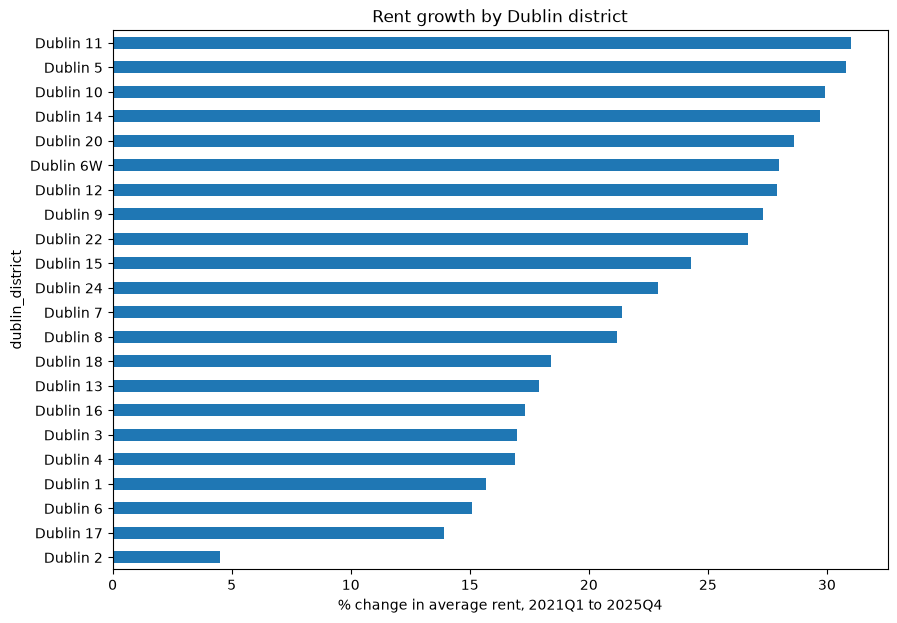

In [12]:
# Rent change per district from 2021Q1 to 2025Q4, as a quick sense check

first = headline[headline['quarter'] == '2021Q1'].set_index('dublin_district')['avg_rent']
last = headline[headline['quarter'] == '2025Q4'].set_index('dublin_district')['avg_rent']

change = ((last - first) / first * 100).round(1).sort_values()

plt.figure(figsize=(10, 7))
change.plot(kind='barh')
plt.xlabel('% change in average rent, 2021Q1 to 2025Q4')
plt.title('Rent growth by Dublin district')
plt.show()

In [13]:
# Column order for the full clean table: location first, then details, then rent

rent_clean = rent[['nation', 'province', 'county', 'county_id', 'local_authority',
                   'dublin_district', 'district_id', 'location', 'location_level',
                   'quarter', 'year', 'quarter_no', 'bedrooms', 'property_type',
                   'is_all_homes', 'avg_rent']]

print(rent_clean.shape)
rent_clean.info()

(27319, 16)
<class 'pandas.DataFrame'>
RangeIndex: 27319 entries, 0 to 27318
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   nation           27319 non-null  str    
 1   province         27319 non-null  str    
 2   county           27319 non-null  str    
 3   county_id        27319 non-null  int64  
 4   local_authority  0 non-null      float64
 5   dublin_district  26494 non-null  str    
 6   district_id      26494 non-null  float64
 7   location         27319 non-null  str    
 8   location_level   27319 non-null  str    
 9   quarter          27319 non-null  str    
 10  year             27319 non-null  int64  
 11  quarter_no       27319 non-null  int64  
 12  bedrooms         27319 non-null  str    
 13  property_type    27319 non-null  str    
 14  is_all_homes     27319 non-null  int64  
 15  avg_rent         27319 non-null  float64
dtypes: float64(3), int64(4), str(9)
memory usage: 3.3 MB


In [14]:
# Saving both tables.

save_folder = dublin_clean + r'\rent'
os.makedirs(save_folder, exist_ok=True)

rent_clean.to_csv(save_folder + r'\rent_dublin_clean.csv', index=False)
headline.to_csv(save_folder + r'\rent_district_headline.csv', index=False)

print('Saved', rent_clean.shape, 'to', save_folder + r'\rent_dublin_clean.csv')
print('Saved', headline.shape, 'to', save_folder + r'\rent_district_headline.csv')

Saved (27319, 16) to C:\Users\LENOVO\OneDrive\OneDrive - National College of Ireland\Machine_learning_Project\just_dublin_dataset\Just_dublin_clean_dataset\rent\rent_dublin_clean.csv
Saved (440, 12) to C:\Users\LENOVO\OneDrive\OneDrive - National College of Ireland\Machine_learning_Project\just_dublin_dataset\Just_dublin_clean_dataset\rent\rent_district_headline.csv
